# Swell Forecast Data Extraction: Workflow Documentation & Analysis

## 0. Notebook Overview

### What this notebook does
This notebook documents and reproduces the full workflow used in the `swell_forecast_extractor.py` script.

### Expected input files
- **Script**: `swell_forecast_extractor.py`
- **CSV**: `swell_forecast_extractor.csv`

### Geographic region & sites
- **Region**: Southern California coastal waters
- **Bounding Box**: `[-120.77, -118.99, 34.73, 33.80]`
- **Sites**: C St. (Ventura), Devereaux (Santa Barbara)

In [1]:
# FILE PATH CONFIGURATION
SCRIPT_PATH = "swell_forecast_extractor.py"
CSV_PATH = "swell_forecast_extractor.csv"
SITE_COL = "site_name"
TIME_COL = "timestamp_local"
SWELL_HEIGHT_COL = "swell_height_m"
BBOX = [-120.77405702695488, -118.99968426997366, 34.73458619896702, 33.80267649583392]

## 1. Common Setup and Shared Helpers

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import warnings
from datetime import datetime

try:
    import folium
    FOLIUM_AVAILABLE = True
except ImportError:
    FOLIUM_AVAILABLE = False
    print("Warning: folium not installed. pip install folium")

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
print(f"Folium available: {FOLIUM_AVAILABLE}")

Folium available: False


In [3]:
LON_MIN, LON_MAX, LAT_MAX, LAT_MIN = BBOX

SITES = {
    "C st.": {"lat": 34.26343870100869, "lon": -119.30167128264624},
    "Devereaux": {"lat": 34.40313812226568, "lon": -119.8780802047039}
}

MODEL_COLORS = {
    "MeteoFrance MFWAM": "#1f77b4",
    "ECMWF WAM 9km": "#ff7f0e",
    "ECMWF WAM 25km": "#2ca02c",
    "DWD GWAM": "#d62728",
    "CDIP MOP California Grid Forecast": "#9467bd",
    "CDIP MOP Forecast Stn 071": "#8c564b",
    "CDIP MOP Forecast Stn 103": "#e377c2",
    "CDIP MOP Forecast Stn 203": "#7f7f7f"
}

In [4]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371
    lat1_rad, lat2_rad = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat/2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon/2)**2
    return R * 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))

def create_model_grid(resolution_km, bbox):
    lon_min, lon_max, lat_max, lat_min = bbox
    lat_center = (lat_max + lat_min) / 2
    deg_per_km_lat = 1 / 111.0
    deg_per_km_lon = 1 / (111.0 * np.cos(np.radians(lat_center)))
    grid_spacing_lat = resolution_km * deg_per_km_lat
    grid_spacing_lon = resolution_km * deg_per_km_lon
    lats = np.arange(lat_min, lat_max + grid_spacing_lat, grid_spacing_lat)
    lons = np.arange(lon_min, lon_max + grid_spacing_lon, grid_spacing_lon)
    return lats, lons, grid_spacing_lat, grid_spacing_lon

def get_nearest_grid_point(site_lat, site_lon, grid_lats, grid_lons):
    lat_idx = np.argmin(np.abs(np.array(grid_lats) - site_lat))
    lon_idx = np.argmin(np.abs(np.array(grid_lons) - site_lon))
    nearest_lat, nearest_lon = grid_lats[lat_idx], grid_lons[lon_idx]
    distance = haversine_distance(site_lat, site_lon, nearest_lat, nearest_lon)
    return nearest_lat, nearest_lon, lat_idx, lon_idx, distance

In [5]:
df = pd.read_csv(CSV_PATH)
df['timestamp'] = pd.to_datetime(df[TIME_COL], format='ISO8601')
print(f"Data loaded: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Time range: {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Sites: {df[SITE_COL].unique().tolist()}")
print(f"Models: {df['model'].unique().tolist()}")

Data loaded: 2770 rows x 30 columns
Time range: 2026-01-18 00:00:00 to 2026-02-01 16:00:00
Sites: ['C st.', 'Devereaux']
Models: ['CDIP MOP California Grid Forecast', 'CDIP MOP Forecast Stn 103', 'CDIP MOP Forecast Stn 203', 'DWD GWAM', 'ECMWF WAM 25km', 'ECMWF WAM 9km', 'MeteoFrance MFWAM', 'CDIP MOP Forecast Stn 071']


## 2. Wave Height vs Swell Height: Variable Clarification

### Understanding Sea State Components

| Component | Description |
|-----------|-------------|
| **Wind Waves** | Locally generated by current winds |
| **Swell** | Long-period waves from distant storms |
| **Combined Waves** | Total Hs = sqrt(Hs_swell^2 + Hs_wind^2) |

### Open-Meteo API Variable Mapping

| Original API Variable | CSV Column | Description |
|----------------------|------------|-------------|
| `wave_height` | `wave_height_m` | Combined significant wave height (Hs) |
| `wave_direction` | `wave_direction_deg` | Combined wave direction |
| `wave_period` | `wave_period_s` | Combined wave period |
| `wind_wave_height` | `wind_wave_height_m` | Wind wave height |
| `wind_wave_direction` | `wind_wave_direction_deg` | Wind wave direction |
| `wind_wave_period` | `wind_wave_period_s` | Wind wave period |
| `wind_wave_peak_period` | `wind_wave_peak_period_s` | Wind wave peak period |
| `swell_wave_height` | `swell_height_m` | **Primary swell height** |
| `swell_wave_direction` | `swell_direction_deg` | Primary swell direction |
| `swell_wave_period` | `swell_period_s` | Primary swell period |
| `swell_wave_peak_period` | `swell_peak_period_s` | Primary swell peak period |
| `secondary_swell_wave_height` | `secondary_swell_height_m` | Secondary swell |
| `tertiary_swell_wave_height` | `tertiary_swell_height_m` | Tertiary swell (GFS only) |

### CDIP NetCDF Variable Mapping

| Original Variable | CSV Column | Description |
|------------------|------------|-------------|
| `waveHs` | `wave_height_m` AND `swell_height_m` | Significant wave height (same value for both) |
| `waveTp` | `wave_period_s` AND `swell_period_s` | Peak period |
| `waveDp` | `wave_direction_deg` AND `swell_direction_deg` | Peak direction |
| `waveTa` | (fallback) | Average period |
| `waveTime` | `timestamp_local` | Forecast time |
| `metaLatitude` | (internal) | Grid latitudes |
| `metaLongitude` | (internal) | Grid longitudes |

**Key Point**: CDIP does NOT partition waves. `swell_height_m` = `wave_height_m` for CDIP sources.

In [6]:
print("WAVE HEIGHT vs SWELL HEIGHT COMPARISON")
print("=" * 60)

print("\n--- Open-Meteo Models (partitioned) ---")
for model in ['MeteoFrance MFWAM', 'ECMWF WAM 9km', 'DWD GWAM']:
    m_df = df[df['model'] == model]
    if len(m_df) > 0:
        wh = m_df['wave_height_m'].dropna()
        sh = m_df['swell_height_m'].dropna()
        print(f"\n{model}:")
        print(f"  wave_height_m (combined): mean={wh.mean():.3f}m")
        print(f"  swell_height_m (primary): mean={sh.mean():.3f}m")

print("\n--- CDIP Models (combined only) ---")
for model in [m for m in df['model'].unique() if 'CDIP' in m]:
    m_df = df[df['model'] == model]
    same = (m_df['wave_height_m'] == m_df['swell_height_m']).all()
    print(f"{model}: wave_height = swell_height? {same}")

WAVE HEIGHT vs SWELL HEIGHT COMPARISON

--- Open-Meteo Models (partitioned) ---

MeteoFrance MFWAM:
  wave_height_m (combined): mean=0.811m
  swell_height_m (primary): mean=0.695m

ECMWF WAM 9km:
  wave_height_m (combined): mean=0.732m
  swell_height_m (primary): mean=nanm

DWD GWAM:
  wave_height_m (combined): mean=1.012m
  swell_height_m (primary): mean=1.011m

--- CDIP Models (combined only) ---
CDIP MOP California Grid Forecast: wave_height = swell_height? True
CDIP MOP Forecast Stn 103: wave_height = swell_height? True
CDIP MOP Forecast Stn 203: wave_height = swell_height? True
CDIP MOP Forecast Stn 071: wave_height = swell_height? True


## 3. Per-Model Documentation

| Model | Source | Provider | Resolution | Forecast | Swell Partitions |
|-------|--------|----------|------------|----------|------------------|
| MeteoFrance MFWAM | Open-Meteo | Copernicus | ~8 km | 10 days | Primary + Secondary |
| ECMWF WAM 9km | Open-Meteo | ECMWF | ~9 km | 15 days | Primary only |
| ECMWF WAM 25km | Open-Meteo | ECMWF | ~25 km | 15 days | Primary only |
| DWD GWAM | Open-Meteo | DWD | ~25 km | 4 days | Primary only |
| CDIP MOP Grid | THREDDS | Scripps | ~1 km | ~7 days | None (combined) |
| CDIP MOP Station | THREDDS | Scripps | Point | ~7-10 days | None (combined) |

In [7]:
print("STATISTICAL SUMMARY BY MODEL")
print("=" * 80)
for model in df['model'].unique():
    m_df = df[df['model'] == model]
    sh = m_df['swell_height_m'].dropna()
    print(f"\n{model}:")
    print(f"  Records: {len(m_df)}, Time: {m_df['timestamp'].min()} to {m_df['timestamp'].max()}")
    if len(sh) > 0:
        print(f"  swell_height_m: mean={sh.mean():.2f}, std={sh.std():.2f}, min={sh.min():.2f}, max={sh.max():.2f}")

STATISTICAL SUMMARY BY MODEL

CDIP MOP California Grid Forecast:
  Records: 32, Time: 2026-01-18 07:00:00 to 2026-01-22 01:00:00
  swell_height_m: mean=0.44, std=0.10, min=0.26, max=0.60

CDIP MOP Forecast Stn 103:
  Records: 168, Time: 2026-01-18 08:00:00 to 2026-01-25 07:00:00
  swell_height_m: mean=0.30, std=0.03, min=0.25, max=0.35

CDIP MOP Forecast Stn 203:
  Records: 336, Time: 2026-01-18 08:00:00 to 2026-01-25 07:00:00
  swell_height_m: mean=0.81, std=0.13, min=0.58, max=1.07

DWD GWAM:
  Records: 240, Time: 2026-01-18 00:00:00 to 2026-01-22 23:00:00
  swell_height_m: mean=1.01, std=0.28, min=0.36, max=1.46

ECMWF WAM 25km:
  Records: 704, Time: 2026-01-18 00:00:00 to 2026-02-01 15:00:00

ECMWF WAM 9km:
  Records: 706, Time: 2026-01-18 00:00:00 to 2026-02-01 16:00:00

MeteoFrance MFWAM:
  Records: 416, Time: 2026-01-18 00:00:00 to 2026-01-26 15:00:00
  swell_height_m: mean=0.70, std=0.23, min=0.34, max=1.26

CDIP MOP Forecast Stn 071:
  Records: 168, Time: 2026-01-18 08:00:00 t

## 4. Spatial Extraction: Interactive Leaflet Maps

Each map shows:
- Model grid cells (blue rectangles)
- Site locations (red stars)
- Selected pixels for each site (yellow highlighted cells)
- Satellite/terrain basemap

In [21]:
def create_model_map(model_name, resolution_km, sites, bbox):
    if not FOLIUM_AVAILABLE:
        print(f"Folium not available for {model_name}")
        return None, []
    
    lon_min, lon_max, lat_max, lat_min = bbox
    center_lat, center_lon = (lat_max + lat_min) / 2, (lon_max + lon_min) / 2
    
    m = folium.Map(location=[center_lat, center_lon], zoom_start=9, tiles=None)
    
    # Add tile layers
    folium.TileLayer(
        tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
        attr='Esri', name='Satellite', overlay=False
    ).add_to(m)
    folium.TileLayer(
        tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Ocean/World_Ocean_Base/MapServer/tile/{z}/{y}/{x}',
        attr='Esri Ocean', name='Ocean', overlay=False
    ).add_to(m)
    folium.TileLayer('OpenStreetMap', name='Streets').add_to(m)
    
    lats, lons, gs_lat, gs_lon = create_model_grid(resolution_km, bbox)
    
    # Grid layer
    grid_group = folium.FeatureGroup(name=f'Grid (~{resolution_km}km)')
    for lat in lats[::max(1, len(lats)//20)]:
        for lon in lons[::max(1, len(lons)//20)]:
            folium.Rectangle(
                bounds=[[lat-gs_lat/2, lon-gs_lon/2], [lat+gs_lat/2, lon+gs_lon/2]],
                color='#3388ff', fill=True, fill_opacity=0.1, weight=1
            ).add_to(grid_group)
    grid_group.add_to(m)
    
    # Sites and selected pixels
    pixel_info = []
    for site_name, site_info in sites.items():
        site_lat, site_lon = site_info['lat'], site_info['lon']
        nearest_lat, nearest_lon, lat_idx, lon_idx, dist = get_nearest_grid_point(site_lat, site_lon, lats, lons)
        
        pixel_info.append({'site': site_name, 'site_lat': site_lat, 'site_lon': site_lon,
                          'pixel_lat': nearest_lat, 'pixel_lon': nearest_lon,
                          'lat_idx': lat_idx, 'lon_idx': lon_idx, 'distance_km': dist})
        
        # Selected pixel
        folium.Rectangle(
            bounds=[[nearest_lat-gs_lat/2, nearest_lon-gs_lon/2], [nearest_lat+gs_lat/2, nearest_lon+gs_lon/2]],
            color='red', fill=True, fill_color='yellow', fill_opacity=0.5, weight=3,
            popup=f'<b>Selected for {site_name}</b><br>Center: ({nearest_lat:.4f}, {nearest_lon:.4f})<br>Dist: {dist:.2f}km'
        ).add_to(m)
        
        # Site marker
        folium.Marker(
            [site_lat, site_lon],
            popup=f'<b>{site_name}</b><br>({site_lat:.4f}, {site_lon:.4f})',
            icon=folium.Icon(color='red', icon='star', prefix='fa')
        ).add_to(m)
        
        # Line from site to pixel
        folium.PolyLine([[site_lat, site_lon], [nearest_lat, nearest_lon]],
                       color='red', weight=2, dash_array='5,5').add_to(m)
    
    folium.LayerControl().add_to(m)
    
    # Title
    title = f'<div style="position:fixed;top:10px;left:50px;background:white;padding:10px;border:2px solid grey;z-index:9999"><b>{model_name}</b><br>Resolution: ~{resolution_km}km<br>Selection: Nearest neighbor</div>'
    m.get_root().html.add_child(folium.Element(title))
    
    return m, pixel_info

In [ ]:
all_pixel_info = {}
if FOLIUM_AVAILABLE:
    print("MeteoFrance MFWAM (~8km)")
    m, p = create_model_map("MeteoFrance MFWAM", 8, SITES, BBOX)
    all_pixel_info["MeteoFrance MFWAM"] = p
    display(m)

In [10]:
if FOLIUM_AVAILABLE:
    print("ECMWF WAM 9km")
    m, p = create_model_map("ECMWF WAM 9km", 9, SITES, BBOX)
    all_pixel_info["ECMWF WAM 9km"] = p
    display(m)

In [11]:
if FOLIUM_AVAILABLE:
    print("ECMWF WAM 25km")
    m, p = create_model_map("ECMWF WAM 25km", 25, SITES, BBOX)
    all_pixel_info["ECMWF WAM 25km"] = p
    display(m)

In [12]:
if FOLIUM_AVAILABLE:
    print("DWD GWAM (~25km)")
    m, p = create_model_map("DWD GWAM", 25, SITES, BBOX)
    all_pixel_info["DWD GWAM"] = p
    display(m)

In [13]:
if FOLIUM_AVAILABLE:
    print("CDIP MOP California Grid (~1km)")
    m, p = create_model_map("CDIP MOP California Grid", 1, SITES, BBOX)
    all_pixel_info["CDIP MOP Grid"] = p
    display(m)

In [14]:
# Pixel Selection Summary Table
print("PIXEL SELECTION SUMMARY")
print("=" * 100)
rows = []
for model, pixels in all_pixel_info.items():
    for p in pixels:
        rows.append({'Model': model, 'Site': p['site'],
                    'Site Lat': f"{p['site_lat']:.5f}", 'Site Lon': f"{p['site_lon']:.5f}",
                    'Pixel Lat': f"{p['pixel_lat']:.5f}", 'Pixel Lon': f"{p['pixel_lon']:.5f}",
                    'Index (i,j)': f"({p['lat_idx']},{p['lon_idx']})", 'Dist (km)': f"{p['distance_km']:.2f}"})
if rows:
    display(pd.DataFrame(rows))

PIXEL SELECTION SUMMARY


In [15]:
# CDIP Buoy Information
buoy_df = df[df['buoy_id'].notna()][['buoy_id', 'buoy_name', 'buoy_distance_km', 'site_name']].drop_duplicates()
if len(buoy_df) > 0:
    print("CDIP BUOY STATIONS USED")
    print("=" * 80)
    display(buoy_df)

CDIP BUOY STATIONS USED


,buoy_id,buoy_name,buoy_distance_km,site_name
16,103.0,"TOPANGA NEARSHORE, CA BUOY - 103p1",71.8,C st.
184,203.0,"SANTA CRUZ BASIN, CA BUOY - 203p1",60.1,C st.
1401,71.0,"HARVEST, CA BUOY - 071p1",82.9,Devereaux
1569,203.0,"SANTA CRUZ BASIN, CA BUOY - 203p1",76.3,Devereaux


## 5. Combined Visualization

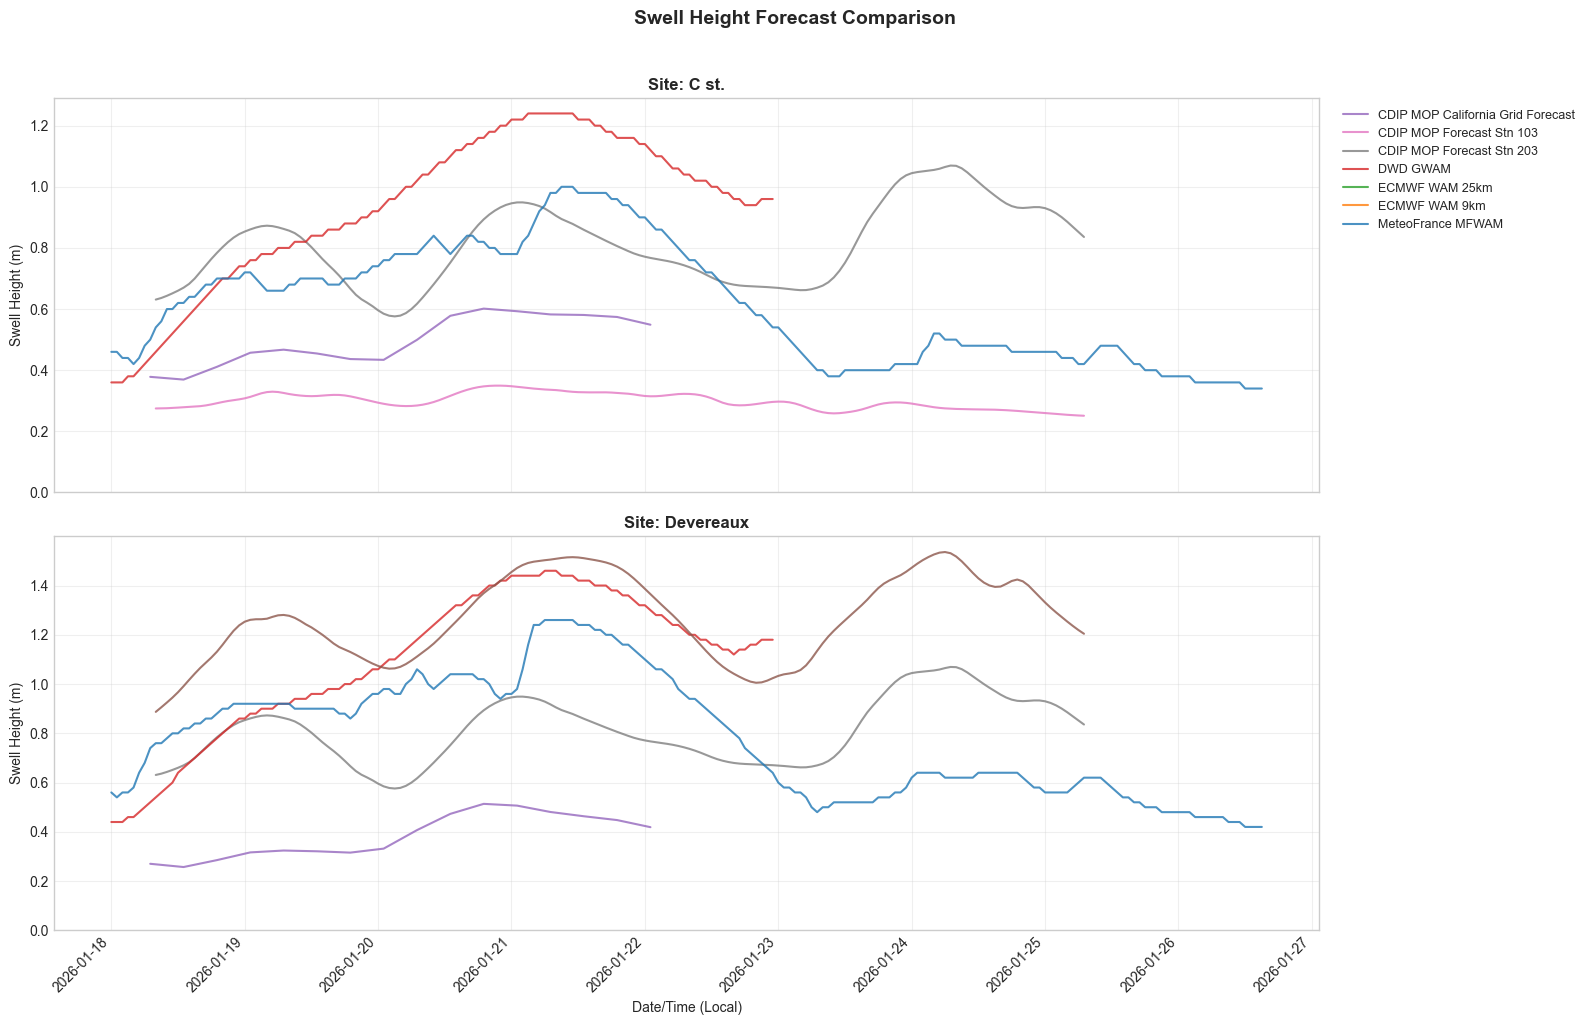

In [16]:
sites = df[SITE_COL].unique()
models = df['model'].unique()
n_sites = len(sites)

fig, axes = plt.subplots(n_sites, 1, figsize=(16, 5*n_sites), sharex=True)
if n_sites == 1: axes = [axes]

for idx, site in enumerate(sites):
    ax = axes[idx]
    site_df = df[df[SITE_COL] == site]
    
    for model in models:
        m_df = site_df[site_df['model'] == model].sort_values('timestamp')
        if len(m_df) == 0: continue
        color = MODEL_COLORS.get(model, '#333')
        ax.plot(m_df['timestamp'], m_df[SWELL_HEIGHT_COL], label=model, color=color, linewidth=1.5, alpha=0.8)
    
    ax.set_ylabel('Swell Height (m)')
    ax.set_title(f'Site: {site}', fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)
    if idx == 0: ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)

axes[-1].set_xlabel('Date/Time (Local)')
plt.xticks(rotation=45, ha='right')
fig.suptitle('Swell Height Forecast Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

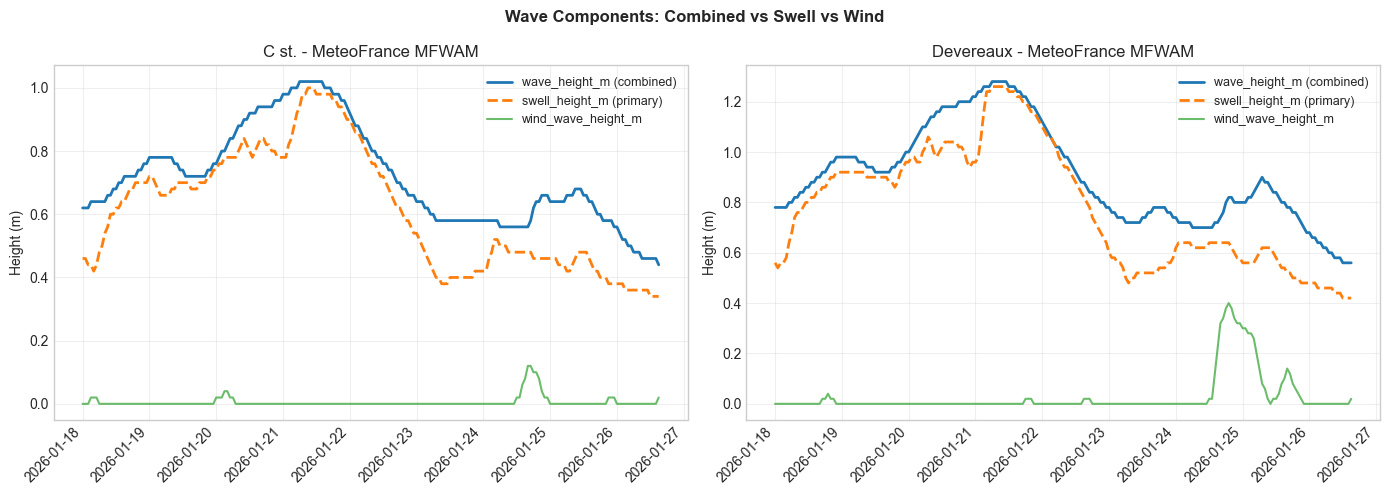

In [17]:
# Wave components comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for idx, site in enumerate(sites):
    ax = axes[idx]
    m_df = df[(df[SITE_COL] == site) & (df['model'] == 'MeteoFrance MFWAM')].sort_values('timestamp')
    if len(m_df) > 0:
        ax.plot(m_df['timestamp'], m_df['wave_height_m'], label='wave_height_m (combined)', linewidth=2)
        ax.plot(m_df['timestamp'], m_df['swell_height_m'], label='swell_height_m (primary)', linestyle='--', linewidth=2)
        ax.plot(m_df['timestamp'], m_df['wind_wave_height_m'], label='wind_wave_height_m', alpha=0.7)
    ax.set_title(f'{site} - MeteoFrance MFWAM')
    ax.legend(fontsize=9)
    ax.set_ylabel('Height (m)')
    ax.grid(True, alpha=0.3)
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
plt.suptitle('Wave Components: Combined vs Swell vs Wind', fontweight='bold')
plt.tight_layout()
plt.show()

In [18]:
# Summary statistics
print("SUMMARY STATISTICS BY MODEL AND SITE")
print("=" * 90)
rows = []
for site in sites:
    for model in models:
        subset = df[(df[SITE_COL] == site) & (df['model'] == model)]
        if len(subset) > 0:
            hs = subset[SWELL_HEIGHT_COL].dropna()
            rows.append({'Site': site, 'Model': model, 'N': len(subset),
                        'Min': f"{hs.min():.2f}" if len(hs) else 'N/A',
                        'Max': f"{hs.max():.2f}" if len(hs) else 'N/A',
                        'Mean': f"{hs.mean():.2f}" if len(hs) else 'N/A',
                        'Std': f"{hs.std():.2f}" if len(hs) else 'N/A'})
display(pd.DataFrame(rows))

SUMMARY STATISTICS BY MODEL AND SITE


,Site,Model,N,Min,Max,Mean,Std
0,C st.,CDIP MOP California Grid Forecast,16,0.37,0.60,0.50,0.08
1,C st.,CDIP MOP Forecast Stn 103,168,0.25,0.35,0.30,0.03
2,C st.,CDIP MOP Forecast Stn 203,168,0.58,1.07,0.81,0.13
3,C st.,DWD GWAM,120,0.36,1.24,0.93,0.25
4,C st.,ECMWF WAM 25km,352,N/A,N/A,N/A,N/A
5,C st.,ECMWF WAM 9km,353,N/A,N/A,N/A,N/A
6,C st.,MeteoFrance MFWAM,208,0.34,1.00,0.61,0.19
7,Devereaux,CDIP MOP California Grid Forecast,16,0.26,0.51,0.38,0.09
8,Devereaux,CDIP MOP Forecast Stn 203,168,0.58,1.07,0.81,0.13
9,Devereaux,DWD GWAM,120,0.44,1.46,1.09,0.29


In [19]:
print("\nNOTEBOOK COMPLETE")
print(f"Generated: {datetime.now()}")
print(f"Records: {len(df)}, Sites: {len(sites)}, Models: {len(models)}")


NOTEBOOK COMPLETE
Generated: 2026-01-18 12:09:24.874615
Records: 2770, Sites: 2, Models: 8
